# Section 5 — Least-Squares Best Fit

[← Neville's Method](04_neville_method.ipynb) ·
[Module 2](README.md) ·
[Next: Numerical Differentiation →](06_numerical_differentiation.ipynb)

Interpolation passes through every data point. Least squares instead chooses
parameters that minimize the total squared residual.

For data $(x_i,y_i)$ and model $g(x)$,

$$
SS_{\mathrm{res}}
=
\sum_i\left(y_i-g(x_i)\right)^2.
$$

### Learning goals

- derive least-squares normal equations;
- find best-fit lines and quadratics;
- derive parameters for constrained model families;
- compute residuals and sums of squares;
- interpret $SS_{\mathrm{res}}$, $SS_{\mathrm{reg}}$, $SS_{\mathrm{tot}}$,
  and $R^2$;
- compare models using $R^2$ and residual error.


In [1]:
import matplotlib.pyplot as plt
import numpy as np


## 1. Least-squares line and the normal equations

For

$$
P_1(x)=a_0+a_1x,
$$

minimize

$$
E(a_0,a_1)
=
\sum_{i=1}^n
\left(y_i-a_0-a_1x_i\right)^2.
$$

Set both partial derivatives equal to zero:

$$
\frac{\partial E}{\partial a_0}=0,
\qquad
\frac{\partial E}{\partial a_1}=0.
$$

This gives the normal equations

$$
\begin{aligned}
n a_0+\left(\sum x_i\right)a_1
&=\sum y_i,\\
\left(\sum x_i\right)a_0
+\left(\sum x_i^2\right)a_1
&=\sum x_i y_i.
\end{aligned}
$$


## 2. Least-squares quadratic

For

$$
P_2(x)=a_0+a_1x+a_2x^2,
$$

the normal equations are

$$
\begin{bmatrix}
n & \sum x_i & \sum x_i^2\\
\sum x_i & \sum x_i^2 & \sum x_i^3\\
\sum x_i^2 & \sum x_i^3 & \sum x_i^4
\end{bmatrix}
\begin{bmatrix}
a_0\\a_1\\a_2
\end{bmatrix}
=
\begin{bmatrix}
\sum y_i\\
\sum x_i y_i\\
\sum x_i^2y_i
\end{bmatrix}.
$$

This is the degree-two version of the same least-squares minimization principle.


In [2]:
def polynomial_least_squares(x_data, y_data, degree):
    """Return least-squares polynomial coefficients in ascending order."""
    matrix = np.vander(
        x_data,
        N=degree + 1,
        increasing=True,
    )
    normal_matrix = matrix.T @ matrix
    normal_rhs = matrix.T @ y_data
    return np.linalg.solve(normal_matrix, normal_rhs)


x_data = np.array([1.0, 3.0, 4.0, 5.0, 7.0])
y_data = np.array([2.1, 3.2, 3.9, 4.5, 5.3])

line_coefficients = polynomial_least_squares(
    x_data,
    y_data,
    degree=1,
)
quad_coefficients = polynomial_least_squares(
    x_data,
    y_data,
    degree=2,
)

print("linear coefficients:")
print(line_coefficients)
print("\nquadratic coefficients:")
print(quad_coefficients)


linear coefficients:
[1.62  0.545]

quadratic coefficients:
[ 1.37714286  0.70690476 -0.0202381 ]


## 3. Residual sums and $R^2$

Let $\hat y_i$ be predicted values and

$$
\bar y=\frac1n\sum y_i.
$$

Define

$$
SS_{\mathrm{res}}
=
\sum_i(y_i-\hat y_i)^2,
$$

$$
SS_{\mathrm{tot}}
=
\sum_i(y_i-\bar y)^2,
$$

and, for the usual least-squares model with an intercept,

$$
SS_{\mathrm{reg}}
=
\sum_i(\hat y_i-\bar y)^2.
$$

Then

$$
SS_{\mathrm{tot}}
=
SS_{\mathrm{reg}}
+
SS_{\mathrm{res}},
$$

and

$$
R^2
=
1-\frac{SS_{\mathrm{res}}}{SS_{\mathrm{tot}}}
=
\frac{SS_{\mathrm{reg}}}{SS_{\mathrm{tot}}}.
$$

For comparing the degree-one and degree-two models used in the review, a larger
$R^2$ and smaller $SS_{\mathrm{res}}$ indicate a better fit to the observed
data.


In [3]:
def evaluate_polynomial(coefficients, x_values):
    """Evaluate coefficients stored in ascending power order."""
    values = np.zeros_like(
        np.asarray(x_values, dtype=float)
    )

    for power, coefficient in enumerate(coefficients):
        values += coefficient * np.asarray(x_values) ** power

    return values


def fit_statistics(y_data, y_hat):
    """Return SS_res, SS_reg, SS_tot, and R^2."""
    y_bar = np.mean(y_data)
    ss_res = np.sum((y_data - y_hat) ** 2)
    ss_reg = np.sum((y_hat - y_bar) ** 2)
    ss_tot = np.sum((y_data - y_bar) ** 2)
    r_squared = 1.0 - ss_res / ss_tot
    return ss_res, ss_reg, ss_tot, r_squared


for name, coefficients in [
    ("degree 1", line_coefficients),
    ("degree 2", quad_coefficients),
]:
    y_hat = evaluate_polynomial(
        coefficients,
        x_data,
    )
    statistics = fit_statistics(y_data, y_hat)
    print(name)
    print(f"  SS_res = {statistics[0]:.8f}")
    print(f"  SS_reg = {statistics[1]:.8f}")
    print(f"  SS_tot = {statistics[2]:.8f}")
    print(f"  R^2    = {statistics[3]:.8f}")


degree 1
  SS_res = 0.05950000
  SS_reg = 5.94050000
  SS_tot = 6.00000000
  R^2    = 0.99008333
degree 2
  SS_res = 0.02509524
  SS_reg = 5.97490476
  SS_tot = 6.00000000
  R^2    = 0.99581746


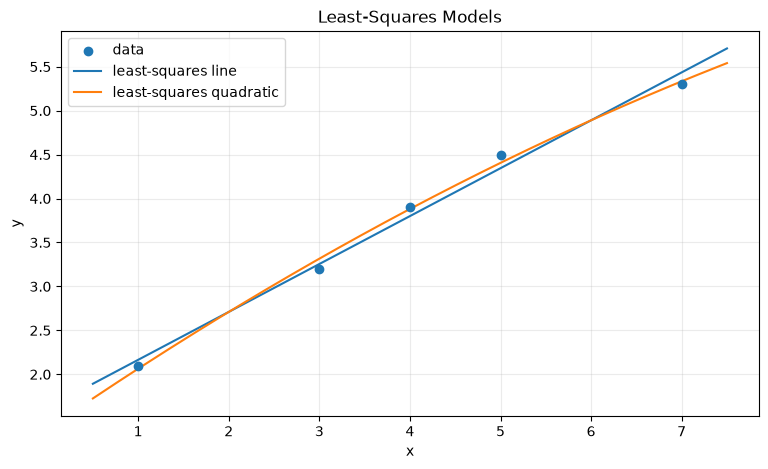

In [4]:
x_plot = np.linspace(0.5, 7.5, 400)

plt.figure(figsize=(9, 5))
plt.scatter(
    x_data,
    y_data,
    zorder=3,
    label="data",
)
plt.plot(
    x_plot,
    evaluate_polynomial(
        line_coefficients,
        x_plot,
    ),
    label="least-squares line",
)
plt.plot(
    x_plot,
    evaluate_polynomial(
        quad_coefficients,
        x_plot,
    ),
    label="least-squares quadratic",
)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Least-Squares Models")
plt.grid(alpha=0.25)
plt.legend()
plt.show()


## 4. Constrained model: $y=ax^2+1$

For the model

$$
g(x)=ax^2+1,
$$

minimize

$$
E(a)
=
\sum_i
\left(y_i-ax_i^2-1\right)^2.
$$

Differentiating and setting $E'(a)=0$ gives

$$
\boxed{
a=
\frac{\sum_i x_i^2(y_i-1)}
{\sum_i x_i^4}
}.
$$


## 5. Constrained model: $y=-x+b$

For

$$
g(x)=-x+b,
$$

the error is

$$
E(b)
=
\sum_i
(y_i+x_i-b)^2.
$$

Setting $E'(b)=0$ gives

$$
\boxed{
b=
\frac1n
\sum_i(y_i+x_i)
}.
$$

These examples illustrate an important numerical-analysis habit:
**write the error function first, then minimize it with respect to the unknown
parameter.**


In [5]:
x_special = np.array([1.0, 2.0, 3.0, 4.0])
y_special = np.array([3.0, 1.0, 2.0, 0.0])

a_value = np.sum(
    x_special**2 * (y_special - 1.0)
) / np.sum(x_special**4)

b_value = np.mean(y_special + x_special)

print(f"best a for y = a x^2 + 1: {a_value:.8f}")
print(f"best b for y = -x + b:    {b_value:.8f}")


best a for y = a x^2 + 1: -0.01412429
best b for y = -x + b:    4.00000000


### References

- Eric Sullivan, *Numerical Methods: An Inquiry-Based Approach with Python*.
- Leon Q. Brin, *Tea Time Numerical Analysis*.
- Richard L. Burden and J. Douglas Faires, *Numerical Analysis*.
- MAD 4401 Exam 2 review and course notes.

[Next: Numerical Differentiation →](06_numerical_differentiation.ipynb)
